# Bank Marketing — Prediction

## 0. Setup

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", None)

RANDOM_STATE = 42
DATA_PATH = "../dataset/bank/bank-full.csv"
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)


def save_fig(name):
    plt.savefig(FIG_DIR / f"{name}.png", dpi=200, bbox_inches="tight")

# 1. Data Preparation

## 1.1 Load

In [2]:
df_raw = pd.read_csv(DATA_PATH, sep=";")
df_raw.shape

(45211, 17)

## 1.2 Column mapping

In [3]:
COLUMN_MAP = {
    "default": "has_credit_default",           # has credit in default? (yes/no)
    "balance": "avg_yearly_balance",           # average yearly balance (euros)
    "housing": "has_housing_loan",             # has housing loan? (yes/no)
    "loan": "has_personal_loan",               # has personal loan? (yes/no)
    "contact": "contact_type",                 # contact communication type: cellular / telephone / unknown
    "day": "last_contact_day",                 # last contact day of month
    "month": "last_contact_month",             # last contact month of year
    "duration": "last_contact_duration",       # last contact duration (seconds); leakage, benchmark only
    "campaign": "n_contacts_this_campaign",    # contacts during this campaign (incl. last contact)
    "pdays": "days_since_prev_campaign",       # days since last contact in a previous campaign (-1 = never)
    "previous": "n_contacts_before_campaign",  # contacts before this campaign
    "poutcome": "prev_campaign_outcome",       # outcome of the previous campaign
    "y": "subscribed_term_deposit",            # target: has the client subscribed a term deposit?
}

df = df_raw.rename(columns=COLUMN_MAP)

## 1.3 Convert yes/no to 1/0

In [4]:
YES_NO_COLS = ["has_credit_default", "has_housing_loan", "has_personal_loan", "subscribed_term_deposit"]

for col in YES_NO_COLS:
    df[col] = df[col].map({"yes": 1, "no": 0})

## 1.4 Drop leakage column

In [5]:
# known only after the call
df = df.drop(columns="last_contact_duration")
df.shape

(45211, 16)

# 2. Feature Engineering

## 2.1 `was_contacted_before`

In [6]:
df["was_contacted_before"] = (df["days_since_prev_campaign"] != -1).astype(int)
df["was_contacted_before"].value_counts()

was_contacted_before
0    36954
1     8257
Name: count, dtype: int64

## 2.2 `days_since_prev_campaign = -1`

In [7]:
df.loc[df["days_since_prev_campaign"] != -1, "days_since_prev_campaign"].describe()

count    8257.000000
mean      224.577692
std       115.344035
min         1.000000
25%       133.000000
50%       194.000000
75%       327.000000
max       871.000000
Name: days_since_prev_campaign, dtype: float64

In [8]:
# 999 > max real value (871): never contacted = longest time ago
df["days_since_prev_campaign"] = df["days_since_prev_campaign"].replace(-1, 999)
df["days_since_prev_campaign"].max()

np.int64(999)

## 2.3 Features & target

In [9]:
TARGET = "subscribed_term_deposit"
CATEGORICAL_COLS = ["job", "marital", "education", "contact_type", "last_contact_month", "prev_campaign_outcome"]
SKEWED_COLS = ["avg_yearly_balance", "n_contacts_this_campaign", "n_contacts_before_campaign"]
NUMERIC_COLS = ["age", "last_contact_day", "days_since_prev_campaign", "was_contacted_before",
                "has_credit_default", "has_housing_loan", "has_personal_loan"]

X = df.drop(columns=TARGET)
y = df[TARGET]
X.shape, len(CATEGORICAL_COLS + SKEWED_COLS + NUMERIC_COLS)

((45211, 16), 16)

## 2.4 Preprocessing

In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler


def signed_log(x):
    return np.sign(x) * np.log1p(np.abs(x))  # balance can be negative


# linear model: one-hot + log for skewed columns + scaling
linear_prep = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL_COLS),
    ("skewed", make_pipeline(FunctionTransformer(signed_log), StandardScaler()), SKEWED_COLS),
    ("num", StandardScaler(), NUMERIC_COLS),
])

# tree models: one-hot only, numbers unchanged
tree_prep = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL_COLS),
], remainder="passthrough")

linear_prep.fit_transform(X).shape, tree_prep.fit_transform(X).shape

((45211, 48), (45211, 48))

# 3. Train / Test Split

## 3.1 Stratified random split

In [11]:
from sklearn.model_selection import StratifiedKFold, train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
X_train.shape, X_test.shape

((36168, 16), (9043, 16))

# 4. Imbalanced Data

## 4.1 Class distribution (train)

In [12]:
y_train.value_counts()

subscribed_term_deposit
0    31937
1     4231
Name: count, dtype: int64

## 4.2 Handling methods (Logistic Regression, 5-fold CV)

In [13]:
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_validate

METRICS = ["accuracy", "precision", "recall", "f1", "roc_auc", "average_precision"]

imbalance_methods = {
    "none": ImbPipeline([
        ("prep", linear_prep),
        ("model", LogisticRegression(max_iter=1000)),
    ]),
    "class_weight": ImbPipeline([
        ("prep", linear_prep),
        ("model", LogisticRegression(class_weight="balanced", max_iter=1000)),
    ]),
    "undersampling": ImbPipeline([
        ("prep", linear_prep),
        ("sampler", RandomUnderSampler(random_state=RANDOM_STATE)),
        ("model", LogisticRegression(max_iter=1000)),
    ]),
    "smote": ImbPipeline([
        ("prep", linear_prep),
        ("sampler", SMOTE(random_state=RANDOM_STATE)),  # oversampling on train folds only
        ("model", LogisticRegression(max_iter=1000)),
    ]),
}

imbalance_results = {}
for method, pipe in imbalance_methods.items():
    scores = cross_validate(pipe, X_train, y_train, cv=CV, scoring=METRICS)
    imbalance_results[method] = {m: scores[f"test_{m}"].mean() for m in METRICS}
pd.DataFrame(imbalance_results).T

,accuracy,precision,recall,f1,roc_auc,average_precision
none,0.892198,0.642415,0.177266,0.277620,0.766079,0.405537
class_weight,0.753871,0.266493,0.629403,0.374380,0.766456,0.402425
undersampling,0.748230,0.263075,0.638859,0.372603,0.766089,0.398359
smote,0.750166,0.261733,0.623496,0.368666,0.761866,0.398623


# 5. Baseline & Models

## 5.0 Evaluation helper

In [14]:
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    RocCurveDisplay,
    accuracy_score,
    average_precision_score,
    classification_report,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import cross_val_score

models = {}      # name -> pipeline fitted on train
cv_pr_auc = {}   # name -> 5-fold CV PR-AUC on train (to pick ensemble members)
results = {}     # (name, set) -> metrics (comparison table)
test_proba = {}  # name -> probabilities on test (comparison chart)


def evaluate(name, model):
    """Fit on train, evaluate on train and test (row 1: train, row 2: test)."""
    cv_pr_auc[name] = cross_val_score(model, X_train, y_train, cv=CV, scoring="average_precision").mean()
    model.fit(X_train, y_train)
    models[name] = model

    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    for row, (set_name, X_set, y_set) in enumerate([("train", X_train, y_train), ("test", X_test, y_test)]):
        proba = model.predict_proba(X_set)[:, 1]
        pred = model.predict(X_set)
        results[(name, set_name)] = {
            "accuracy": accuracy_score(y_set, pred),
            "precision": precision_score(y_set, pred, zero_division=0),
            "recall": recall_score(y_set, pred),
            "f1": f1_score(y_set, pred),
            "roc_auc": roc_auc_score(y_set, proba),
            "pr_auc": average_precision_score(y_set, proba),
        }
        print(set_name)
        print(classification_report(y_set, pred, zero_division=0))
        ConfusionMatrixDisplay.from_predictions(y_set, pred, ax=axes[row, 0], cmap="Blues")
        RocCurveDisplay.from_predictions(y_set, proba, name=set_name, ax=axes[row, 1])
        PrecisionRecallDisplay.from_predictions(y_set, proba, name=set_name, ax=axes[row, 2])
    test_proba[name] = proba
    save_fig(f"5_{name.lower().replace(' ', '_')}")
    plt.show()

## 5.1 Baseline — Dummy

train
              precision    recall  f1-score   support

           0       0.88      1.00      0.94     31937
           1       0.00      0.00      0.00      4231

    accuracy                           0.88     36168
   macro avg       0.44      0.50      0.47     36168
weighted avg       0.78      0.88      0.83     36168

test
              precision    recall  f1-score   support

           0       0.88      1.00      0.94      7985
           1       0.00      0.00      0.00      1058

    accuracy                           0.88      9043
   macro avg       0.44      0.50      0.47      9043
weighted avg       0.78      0.88      0.83      9043



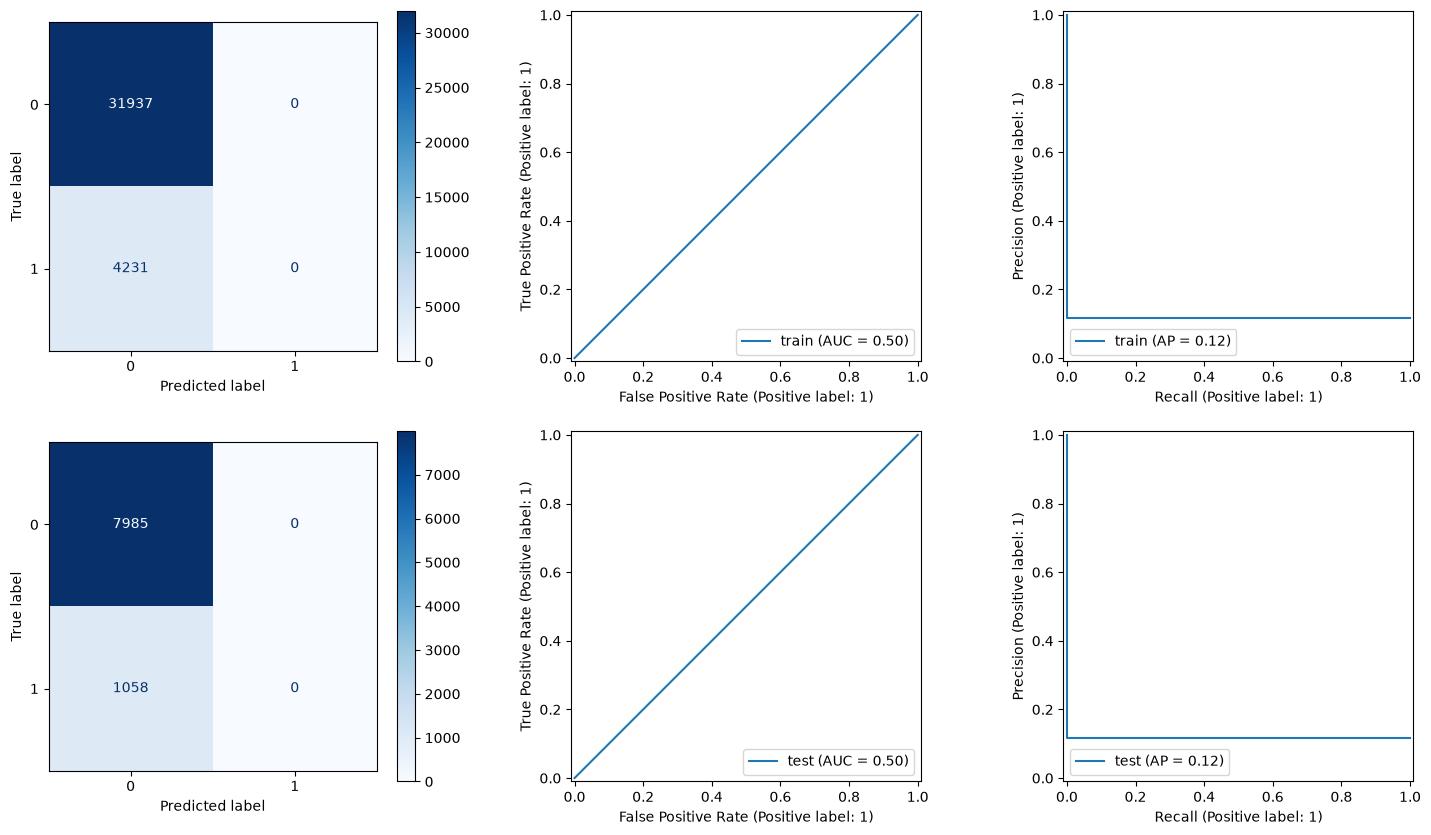

In [15]:
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline

dummy_model = Pipeline([
    ("prep", tree_prep),
    ("model", DummyClassifier()),  # always predicts 0
])
evaluate("Dummy", dummy_model)

## 5.2 Logistic Regression

train
              precision    recall  f1-score   support

           0       0.94      0.77      0.85     31937
           1       0.27      0.64      0.38      4231

    accuracy                           0.76     36168
   macro avg       0.60      0.70      0.61     36168
weighted avg       0.86      0.76      0.79     36168

test
              precision    recall  f1-score   support

           0       0.94      0.77      0.85      7985
           1       0.27      0.64      0.38      1058

    accuracy                           0.75      9043
   macro avg       0.60      0.70      0.61      9043
weighted avg       0.86      0.75      0.79      9043



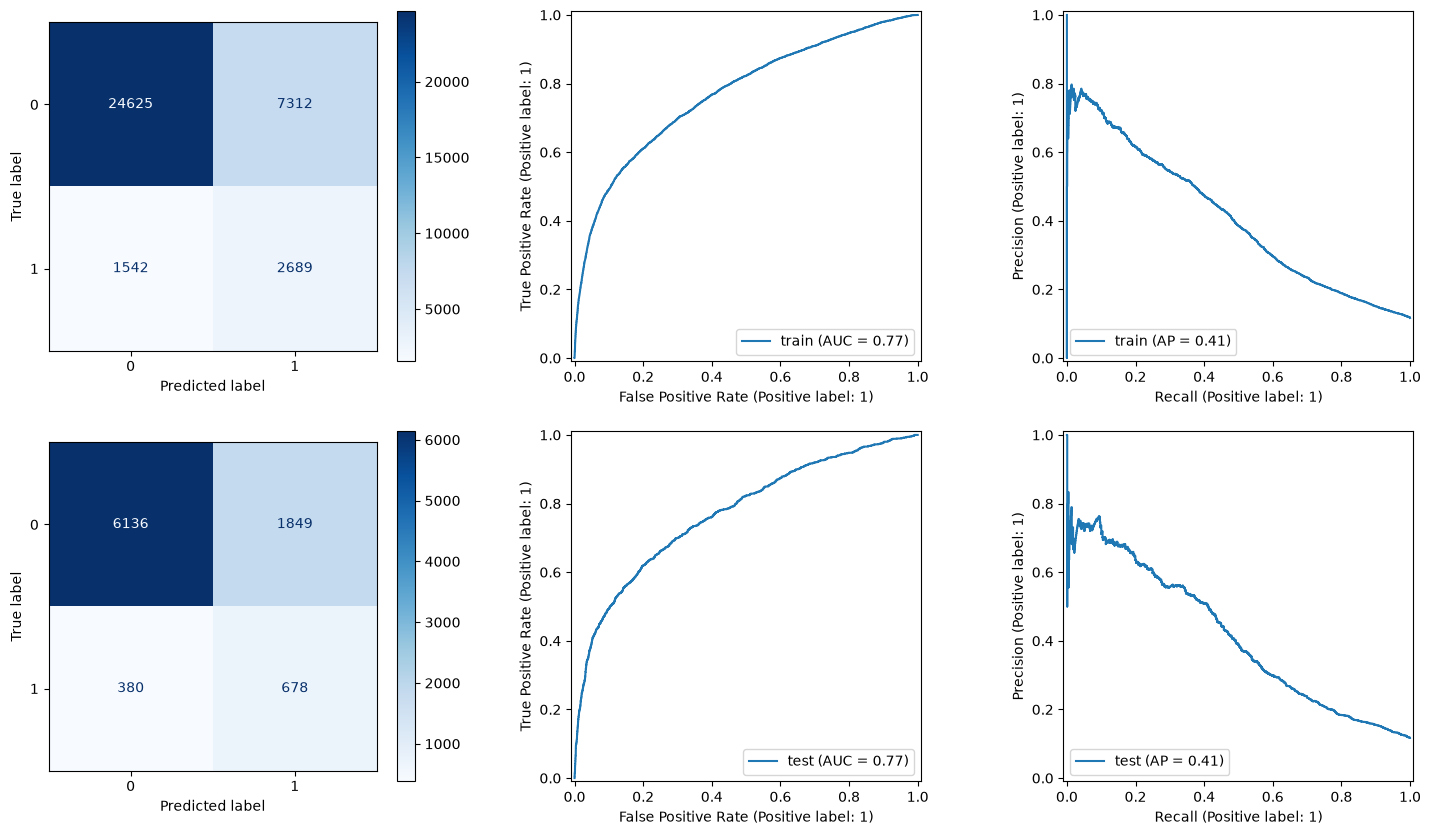

In [16]:
lr_model = Pipeline([
    ("prep", linear_prep),
    ("model", LogisticRegression(class_weight="balanced", max_iter=1000)),
])
evaluate("Logistic Regression", lr_model)

## 5.3 Random Forest

train
              precision    recall  f1-score   support

           0       0.98      0.89      0.93     31937
           1       0.50      0.86      0.63      4231

    accuracy                           0.88     36168
   macro avg       0.74      0.87      0.78     36168
weighted avg       0.92      0.88      0.90     36168



test
              precision    recall  f1-score   support

           0       0.94      0.87      0.91      7985
           1       0.38      0.61      0.47      1058

    accuracy                           0.84      9043
   macro avg       0.66      0.74      0.69      9043
weighted avg       0.88      0.84      0.86      9043



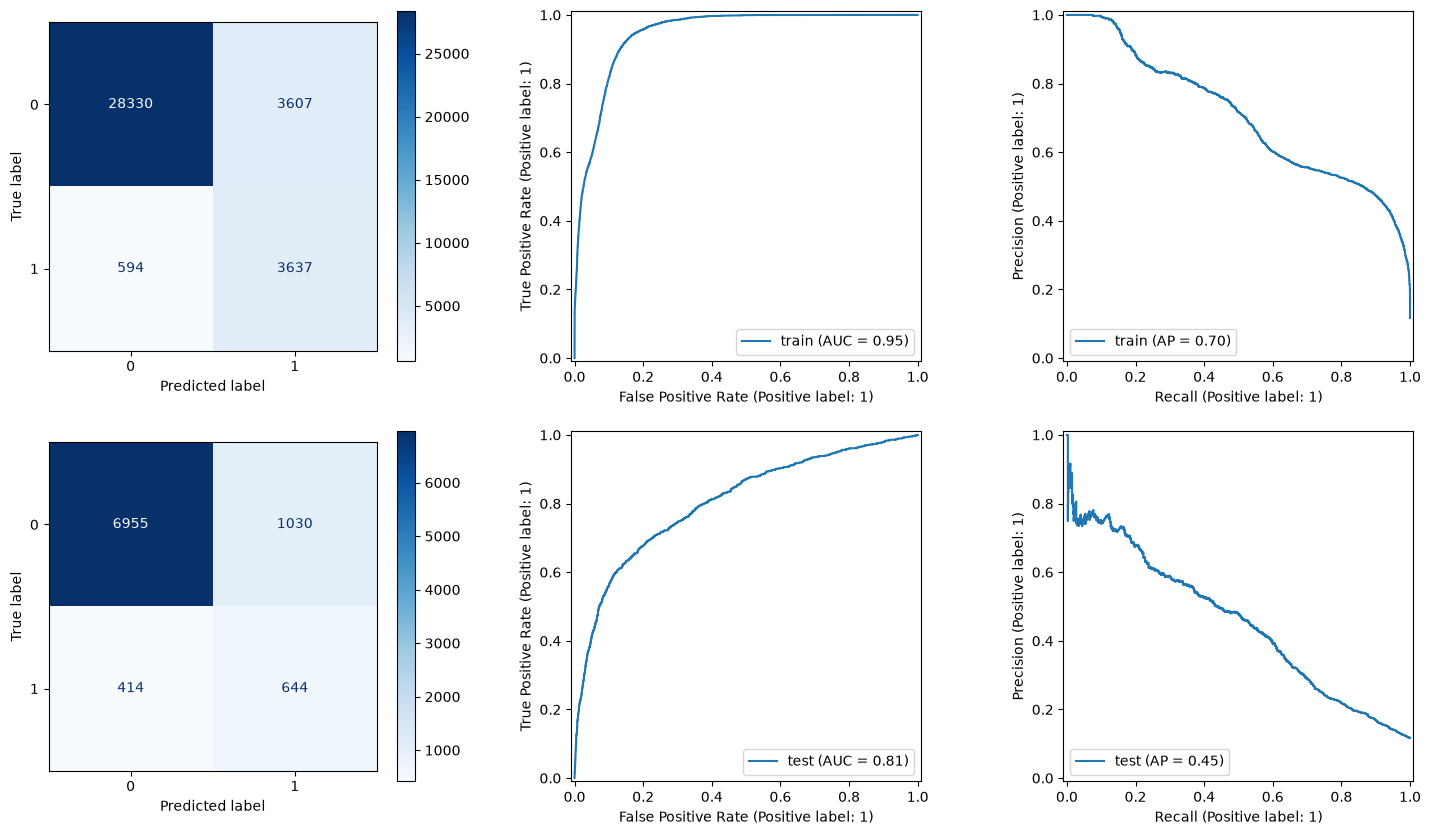

In [17]:
from sklearn.ensemble import RandomForestClassifier

rf_model = Pipeline([
    ("prep", tree_prep),
    ("model", RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=5,
        class_weight="balanced",
        n_jobs=-1,
        random_state=RANDOM_STATE,
    )),
])
evaluate("Random Forest", rf_model)

## 5.4 XGBoost

train
              precision    recall  f1-score   support

           0       0.95      0.86      0.90     31937
           1       0.39      0.69      0.50      4231

    accuracy                           0.84     36168
   macro avg       0.67      0.77      0.70     36168
weighted avg       0.89      0.84      0.85     36168

test
              precision    recall  f1-score   support

           0       0.95      0.85      0.89      7985
           1       0.35      0.64      0.46      1058

    accuracy                           0.82      9043
   macro avg       0.65      0.74      0.67      9043
weighted avg       0.88      0.82      0.84      9043



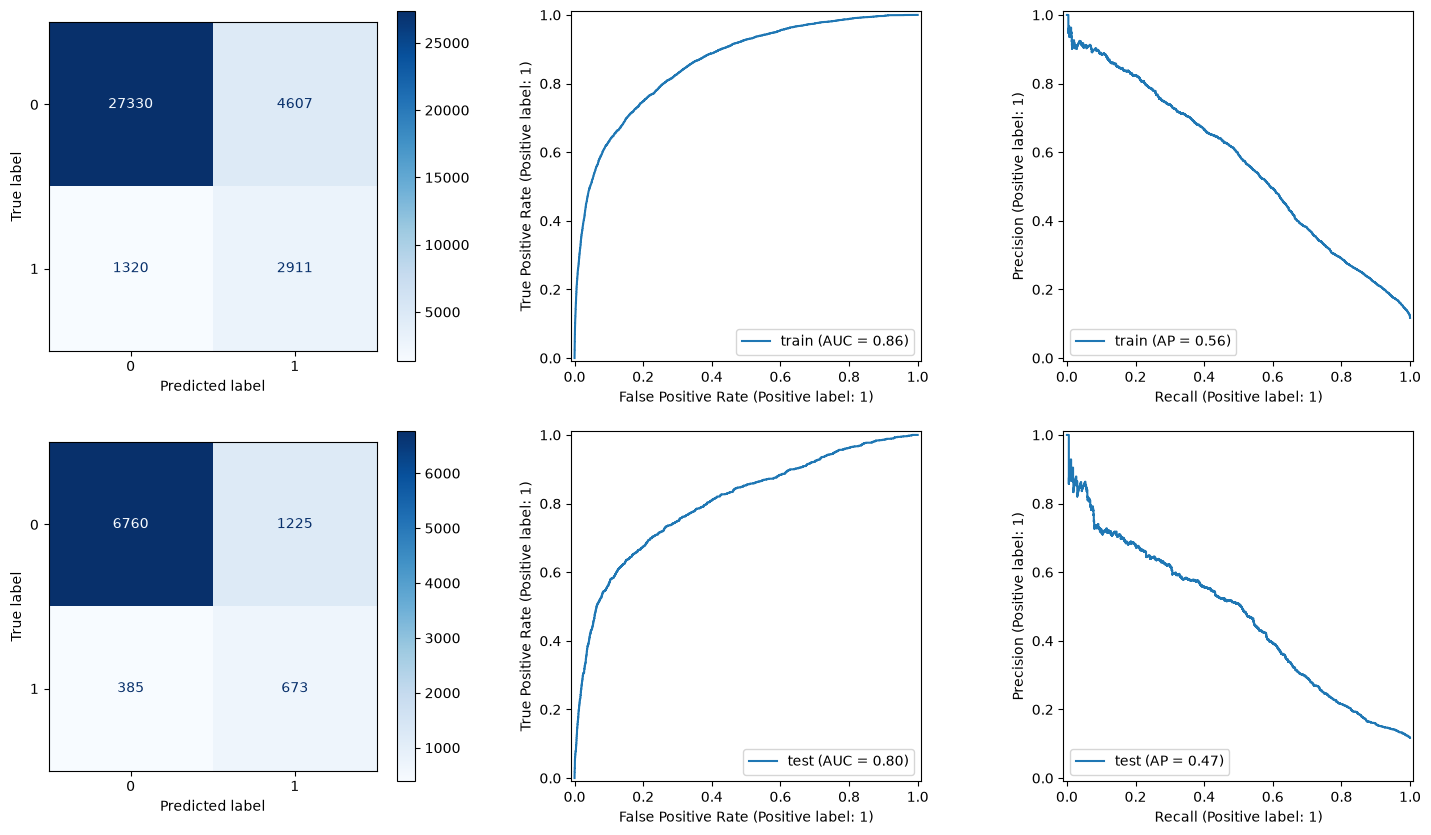

In [18]:
from xgboost import XGBClassifier

NEG_POS_RATIO = (y_train == 0).sum() / (y_train == 1).sum()  # ≈ 7.5, class weight for XGBoost

xgb_model = Pipeline([
    ("prep", tree_prep),
    ("model", XGBClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=5,
        scale_pos_weight=NEG_POS_RATIO,
        n_jobs=-1,
        random_state=RANDOM_STATE,
    )),
])
evaluate("XGBoost", xgb_model)

## 5.5 LightGBM

train
              precision    recall  f1-score   support

           0       0.96      0.87      0.91     31937
           1       0.43      0.75      0.54      4231

    accuracy                           0.85     36168
   macro avg       0.69      0.81      0.73     36168
weighted avg       0.90      0.85      0.87     36168

test
              precision    recall  f1-score   support

           0       0.95      0.86      0.90      7985
           1       0.37      0.64      0.47      1058

    accuracy                           0.83      9043
   macro avg       0.66      0.75      0.68      9043
weighted avg       0.88      0.83      0.85      9043



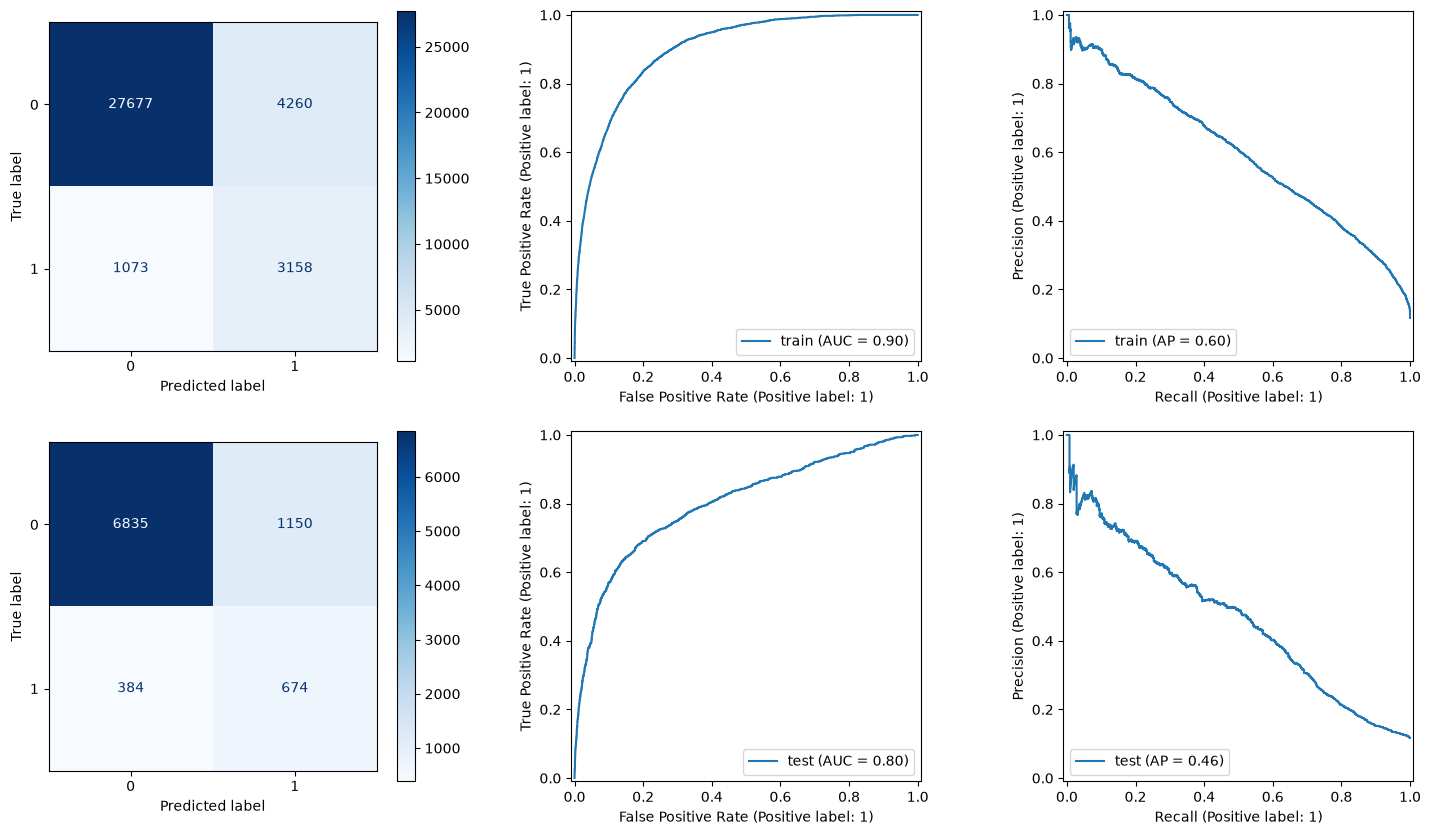

In [19]:
from lightgbm import LGBMClassifier

lgbm_model = Pipeline([
    ("prep", tree_prep),
    ("model", LGBMClassifier(
        n_estimators=300,
        learning_rate=0.05,
        class_weight="balanced",
        verbose=-1,
        random_state=RANDOM_STATE,
    )),
])
evaluate("LightGBM", lgbm_model)

## 5.6 Ensemble members

In [20]:
# top 3 single models by CV PR-AUC on train (Dummy excluded)
top3 = pd.Series(cv_pr_auc).drop("Dummy").sort_values(ascending=False).index[:3].tolist()
top3

['LightGBM', 'Random Forest', 'XGBoost']

## 5.7 Soft Voting

train
              precision    recall  f1-score   support

           0       0.96      0.88      0.92     31937
           1       0.45      0.75      0.56      4231

    accuracy                           0.86     36168
   macro avg       0.71      0.82      0.74     36168
weighted avg       0.90      0.86      0.88     36168



test
              precision    recall  f1-score   support

           0       0.95      0.87      0.91      7985
           1       0.39      0.63      0.48      1058

    accuracy                           0.84      9043
   macro avg       0.67      0.75      0.69      9043
weighted avg       0.88      0.84      0.86      9043



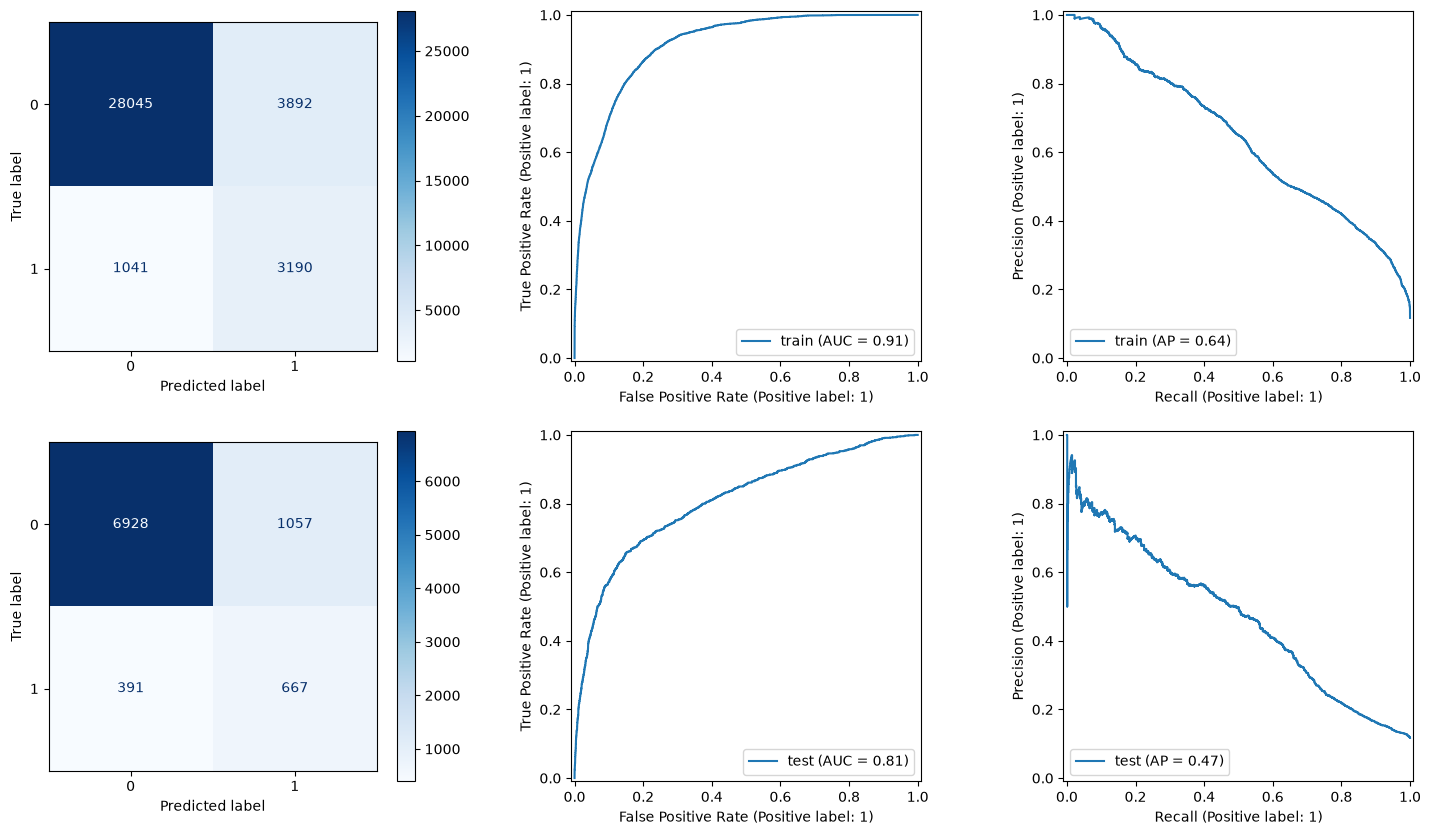

In [21]:
from sklearn.ensemble import VotingClassifier

voting_model = VotingClassifier([(name, models[name]) for name in top3], voting="soft")
evaluate("Soft Voting", voting_model)

## 5.8 Stacking

train
              precision    recall  f1-score   support

           0       0.92      0.98      0.95     31937
           1       0.77      0.38      0.51      4231

    accuracy                           0.91     36168
   macro avg       0.85      0.68      0.73     36168
weighted avg       0.91      0.91      0.90     36168



test
              precision    recall  f1-score   support

           0       0.91      0.98      0.94      7985
           1       0.63      0.27      0.38      1058

    accuracy                           0.90      9043
   macro avg       0.77      0.62      0.66      9043
weighted avg       0.88      0.90      0.88      9043



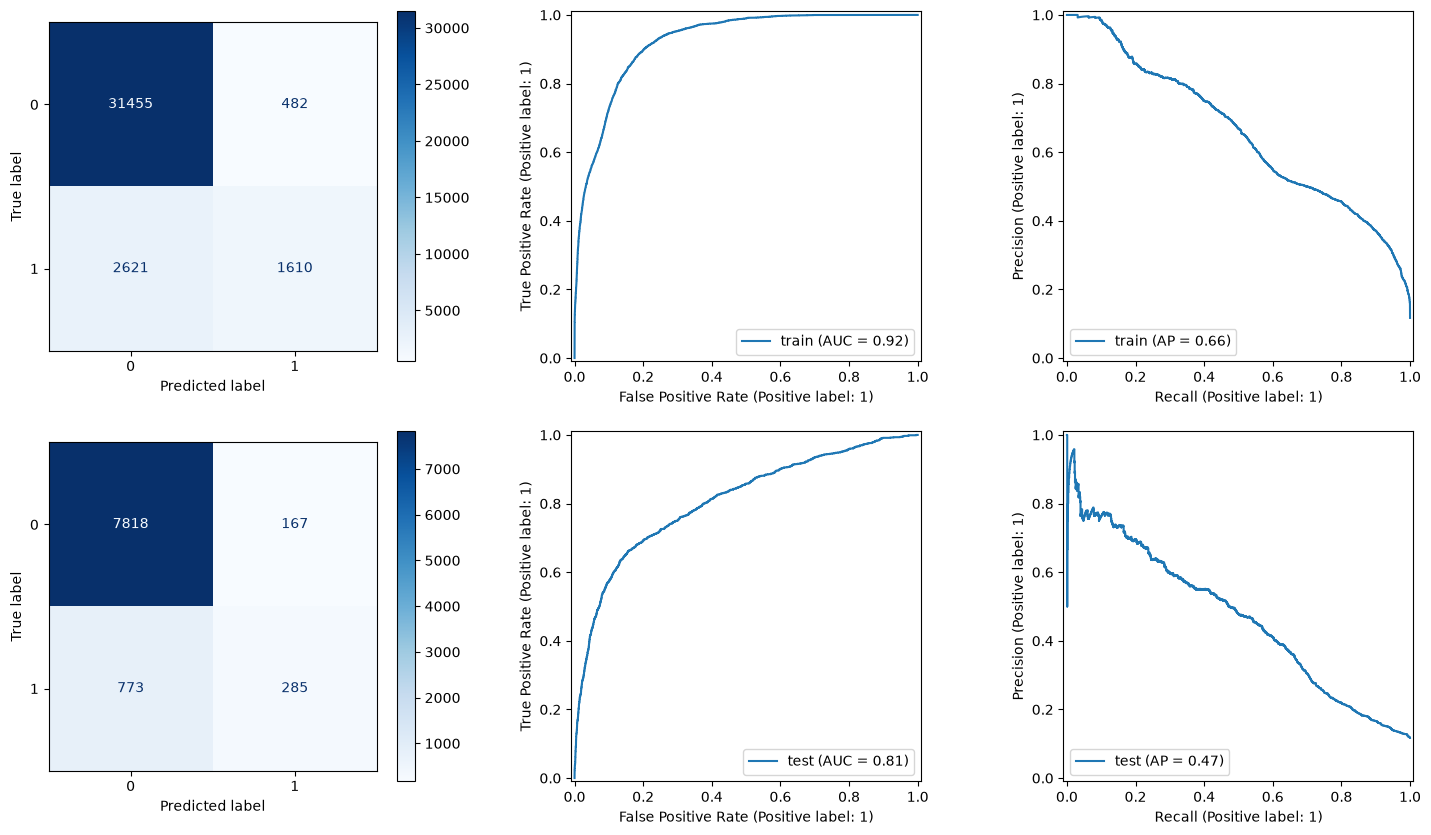

In [22]:
from sklearn.ensemble import StackingClassifier

stacking_model = StackingClassifier(
    [(name, models[name]) for name in top3],
    final_estimator=LogisticRegression(max_iter=1000),
    cv=3,
)
evaluate("Stacking", stacking_model)

## 5.9 Comparison

In [23]:
results_table = pd.DataFrame(results).T
results_table

accuracy  precision    recall        f1   roc_auc  \
Dummy               train  0.883018   0.000000  0.000000  0.000000  0.500000   
                    test   0.883003   0.000000  0.000000  0.000000  0.500000   
Logistic Regression train  0.755198   0.268873  0.635547  0.377881  0.770656   
                    test   0.753511   0.268302  0.640832  0.378243  0.772414   
Random Forest       train  0.883848   0.502071  0.859608  0.633900  0.945454   
                    test   0.840318   0.384707  0.608696  0.471449  0.805066   
XGBoost             train  0.836126   0.387204  0.688017  0.495532  0.860924   
                    test   0.821962   0.354584  0.636106  0.455345  0.803899   
LightGBM            train  0.852549   0.425721  0.746396  0.542192  0.899704   
                    test   0.830366   0.369518  0.637051  0.467731  0.801366   
Soft Voting         train  0.863609   0.450438  0.753959  0.563953  0.912553   
                    test   0.839876   0.386891  0.630435  0.479511  0.808549   
Stacking            train  0.914206   0.769598  0.380525  0.509252  0.922892   
                    test   0.896052   0.630531  0.269376  0.377483  0.808901   

                             pr_auc  
Dummy               train  0.116982  
                    test   0.116997  
Logistic Regression train  0.406013  
                    test   0.412282  
Random Forest       train  0.703782  
                    test   0.454616  
XGBoost             train  0.562013  
                    test   0.465612  
LightGBM            train  0.595967  
                    test   0.464901  
Soft Voting         train  0.638293  
                    test   0.470453  
Stacking            train  0.656389  
                    test   0.468520

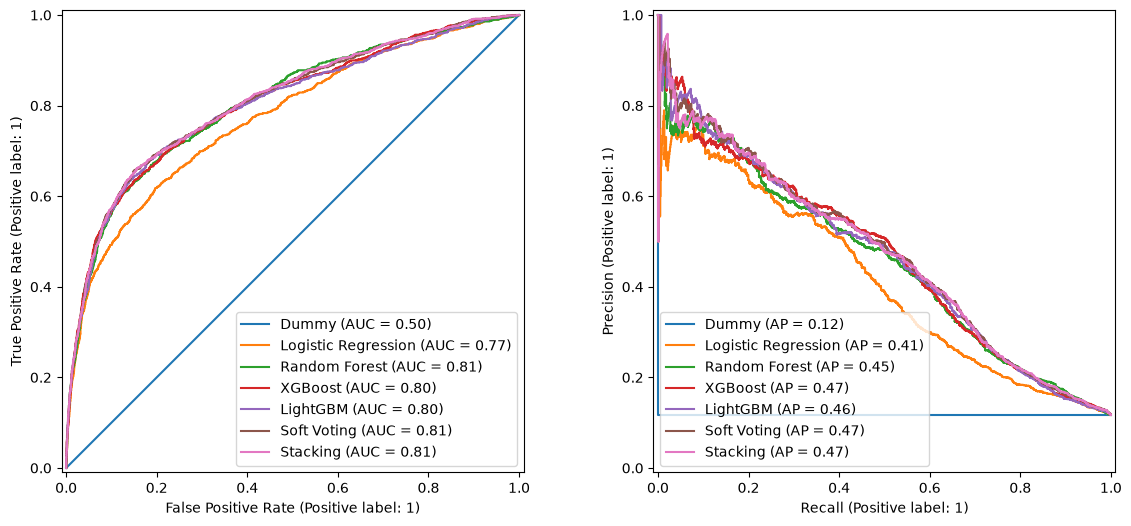

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for name, proba in test_proba.items():
    RocCurveDisplay.from_predictions(y_test, proba, name=name, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(y_test, proba, name=name, ax=axes[1])
save_fig("5.9_model_comparison")
plt.show()